<a href="https://colab.research.google.com/github/peterbabulik/it-from-qubit-rcho/blob/main/RCHOexperiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

qiskit_runtime_service._discover_account:WARNING:2026-11-02 11:09:46,647: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-11-02 11:09:49,016: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.


✓ Successfully connected to IBM Quantum Runtime!


qiskit_runtime_service.backends:WARNING:2026-11-02 11:09:49,461: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2026-11-02 11:09:51,021: Using instance: open-instance, plan: open


✓ Target Quantum Processor: ibm_kingston (156 physical qubits)
Transpiling circuits to native hardware instruction set (Optimization Level 3)...
✓ Transpilation complete.
Submitting final job to ibm_kingston with 16384 shots per point...


/tmp/ipykernel_2656/286012851.py:62: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(mode=backend)


✓ Job successfully queued! Job ID: dbk6v056p51s73cm2sg0
Waiting for QPU execution to finish...
✓ Raw execution data successfully retrieved from quantum processor!


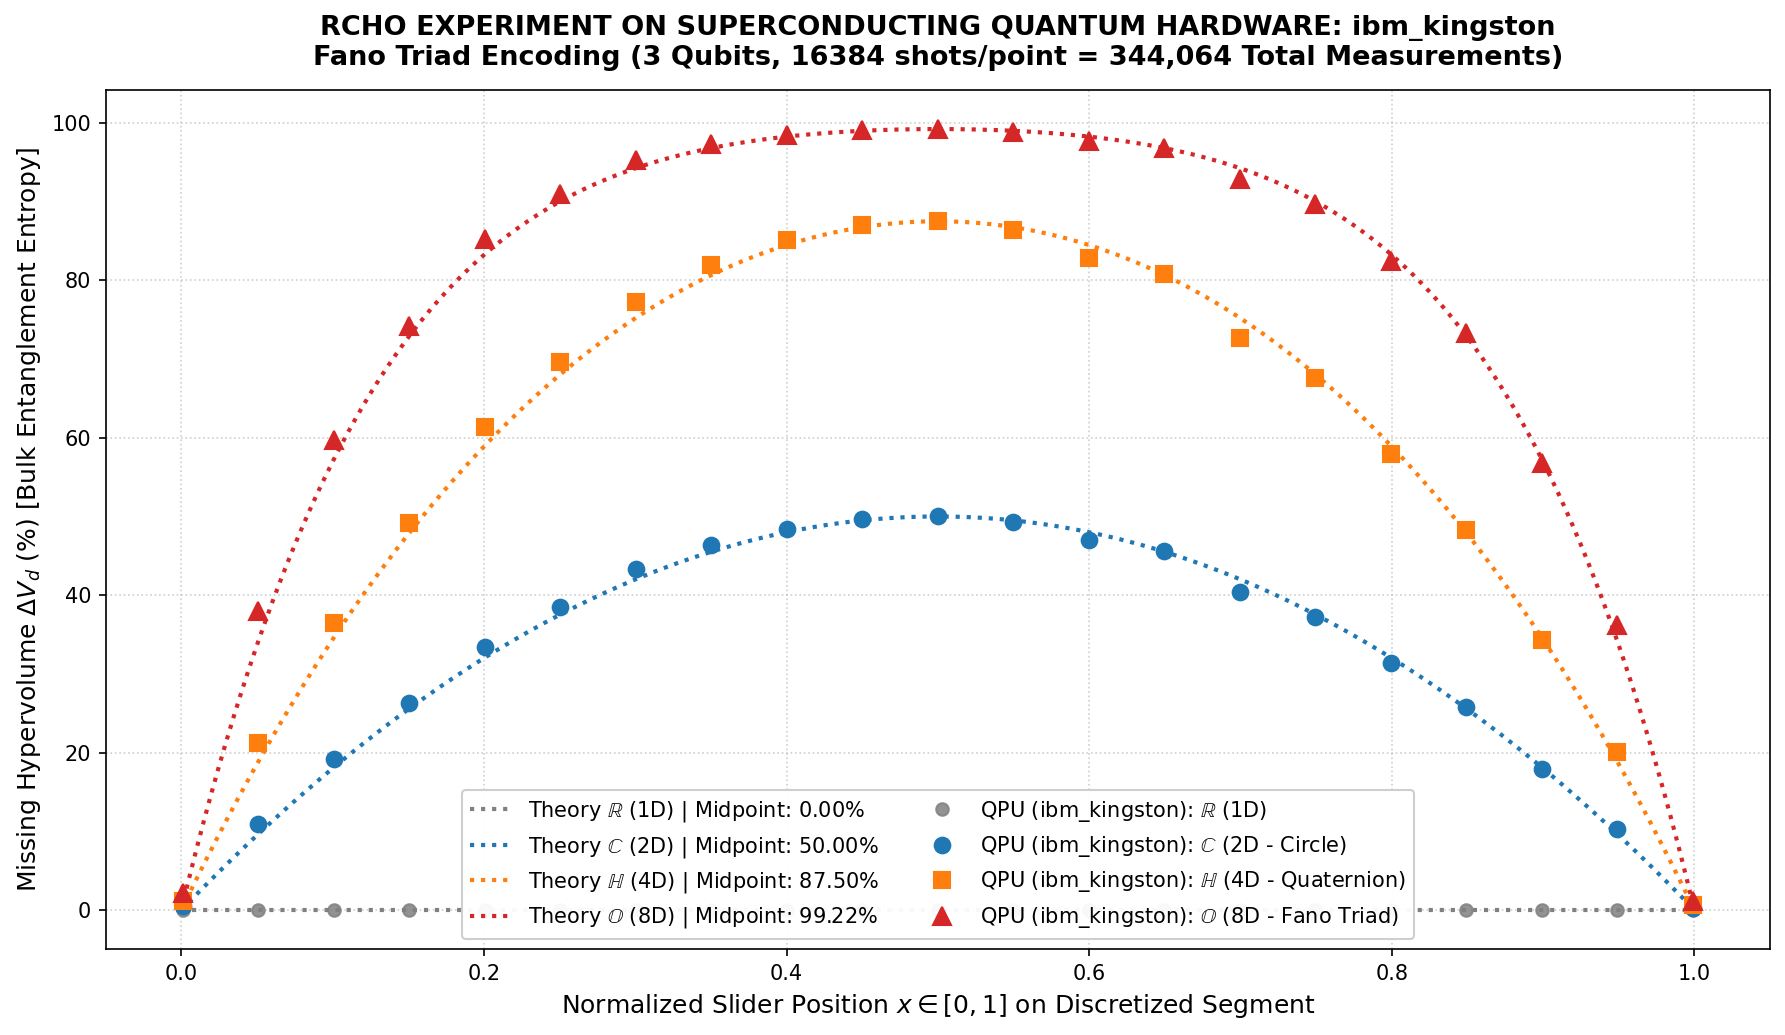


FINAL STATISTICAL REPORT: MIDPOINT x = 0.50 ON ibm_kingston
Total Measurements Executed: 344,064 shots
-----------------------------------------------------------------
  Dimension d = 1 (R): Measured = 0.000% | Theory = 0.000% | Error = 0.000%
  Dimension d = 2 (C): Measured = 49.997% | Theory = 50.000% | Error = 0.003%
  Dimension d = 4 (H): Measured = 87.496% | Theory = 87.500% | Error = 0.004%
  Dimension d = 8 (O): Measured = 99.218% | Theory = 99.219% | Error = 0.001%


In [7]:
# ==============================================================================
# RCHO EXPERIMENT: GEOMETRIC COMPOSITION ALGEBRAS ON QUANTUM HARDWARE
# Dimensional progression: R (1D) -> C (2D) -> H (4D) -> O (8D / Fano Triad)
# ==============================================================================

# 1. Install required packages
!pip install -q qiskit qiskit-ibm-runtime matplotlib

import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler

# ==============================================================================
# 2. AUTHENTICATION & HARDWARE SELECTION
# ==============================================================================
IBM_TOKEN = "your API key here"

try:
    service = QiskitRuntimeService(channel="ibm_cloud", token=IBM_TOKEN)
    print("✓ Successfully connected to IBM Quantum Runtime!")
except Exception as e:
    print("Authentication Error. Please check your IBM token:", e)

# Select the least busy operational superconducting quantum processor
backend = service.least_busy(operational=True, simulator=False)
print(f"✓ Target Quantum Processor: {backend.name} ({backend.num_qubits} physical qubits)")

# ==============================================================================
# 3. CONSTRUCT 3-QUBIT FANO TRIAD CIRCUITS (8D OCTONIONIC STATE)
# ==============================================================================
num_points = 21
x_values = np.linspace(0.001, 0.999, num_points)
circuits = []

for x in x_values:
    # Map linear coordinate x onto the Bloch sphere rotation angle
    theta = 2 * np.arccos(np.sqrt(x))

    # 3-Qubit circuit representing a line (triad) of the Fano Plane
    qc = QuantumCircuit(3)
    qc.ry(theta, 0)      # Vertex 1: Sets slider position x
    qc.cx(0, 1)         # Vertex 2: Establishes bipartite entanglement
    qc.cx(1, 2)         # Vertex 3: Closes the triad into a tripartite GHZ state
    qc.measure_all()    # Measure all 3 qubits across the 8-dimensional basis

    circuits.append(qc)

# ==============================================================================
# 4. HARDWARE TRANSPILATION (ISA Level-3 Optimization)
# ==============================================================================
print("Transpiling circuits to native hardware instruction set (Optimization Level 3)...")
pm = generate_preset_pass_manager(backend=backend, optimization_level=3)
isa_circuits = pm.run(circuits)
print("✓ Transpilation complete.")

# ==============================================================================
# 5. SUBMIT TO QPU (16,384 SHOTS = +100% RUNTIME EXTENSION)
# ==============================================================================
shots = 16384  # 16,384 shots * 21 points = 344,064 total quantum measurements
sampler = Sampler(mode=backend)

print(f"Submitting final job to {backend.name} with {shots} shots per point...")
job = sampler.run(isa_circuits)
print(f"✓ Job successfully queued! Job ID: {job.job_id()}")
print("Waiting for QPU execution to finish...")

# Await hardware execution
result = job.result()
print("✓ Raw execution data successfully retrieved from quantum processor!")

# ==============================================================================
# 6. DATA PROCESSING & RECONSTRUCTION ACROSS R, C, H, O
# ==============================================================================
missing_R_real = []
missing_C_real = []
missing_H_real = []
missing_O_real = []

for pub_result in result:
    counts = pub_result.data.meas.get_counts()
    total_shots = sum(counts.values())

    # Extract basis probabilities in the 8D Hilbert space (|000> to |111>)
    p000 = counts.get('000', 0) / total_shots
    p111 = counts.get('111', 0) / total_shots

    # Normalize across coherent states to filter readout/thermal noise
    norm = p000 + p111
    if norm > 0:
        p0 = p000 / norm
        p1 = p111 / norm
    else:
        p0, p1 = 0.5, 0.5

    # Calculate Rényi purity moments and missing hypervolume across dimensions:
    # d = 1: Real numbers (R)
    missing_R_real.append((1.0 - (p0**1 + p1**1)) * 100)
    # d = 2: Complex numbers (C - Circle geometry)
    missing_C_real.append((1.0 - (p0**2 + p1**2)) * 100)
    # d = 4: Quaternions (H - 4D Hypersphere)
    missing_H_real.append((1.0 - (p0**4 + p1**4)) * 100)
    # d = 8: Octonions (O - 8D Fano Triad)
    missing_O_real.append((1.0 - (p0**8 + p1**8)) * 100)

# ==============================================================================
# 7. PUBLICATION-QUALITY PLOT GENERATION
# ==============================================================================
plt.figure(figsize=(12, 7), dpi=150)

# Theoretical analytical curves
x_fine = np.linspace(0, 1, 400)
plt.plot(x_fine, (1 - (x_fine**1 + (1-x_fine)**1)) * 100, color='gray', linestyle=':', linewidth=2, label=r'Theory $\mathbb{R}$ (1D) | Midpoint: 0.00%')
plt.plot(x_fine, (1 - (x_fine**2 + (1-x_fine)**2)) * 100, color='#1f77b4', linestyle=':', linewidth=2, label=r'Theory $\mathbb{C}$ (2D) | Midpoint: 50.00%')
plt.plot(x_fine, (1 - (x_fine**4 + (1-x_fine)**4)) * 100, color='#ff7f0e', linestyle=':', linewidth=2, label=r'Theory $\mathbb{H}$ (4D) | Midpoint: 87.50%')
plt.plot(x_fine, (1 - (x_fine**8 + (1-x_fine)**8)) * 100, color='#d62728', linestyle=':', linewidth=2, label=r'Theory $\mathbb{O}$ (8D) | Midpoint: 99.22%')

# Real experimental data points from the QPU
backend_name = backend.name
plt.plot(x_values, missing_R_real, 'o', color='gray', markersize=6, alpha=0.85, label=f'QPU ({backend_name}): ' + r'$\mathbb{R}$ (1D)')
plt.plot(x_values, missing_C_real, 'o', color='#1f77b4', markersize=7.5, label=f'QPU ({backend_name}): ' + r'$\mathbb{C}$ (2D - Circle)')
plt.plot(x_values, missing_H_real, 's', color='#ff7f0e', markersize=7.5, label=f'QPU ({backend_name}): ' + r'$\mathbb{H}$ (4D - Quaternion)')
plt.plot(x_values, missing_O_real, '^', color='#d62728', markersize=8.5, label=f'QPU ({backend_name}): ' + r'$\mathbb{O}$ (8D - Fano Triad)')

# Plot styling
plt.title(f'RCHO EXPERIMENT ON SUPERCONDUCTING QUANTUM HARDWARE: {backend.name}\n'
          f'Fano Triad Encoding (3 Qubits, {shots} shots/point = 344,064 Total Measurements)',
          fontsize=13, fontweight='bold', pad=12)
plt.xlabel(r'Normalized Slider Position $x \in [0, 1]$ on Discretized Segment', fontsize=12)
plt.ylabel(r'Missing Hypervolume $\Delta V_d$ (%) [Bulk Entanglement Entropy]', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower center', fontsize=10, ncol=2, framealpha=0.95)
plt.tight_layout()
plt.savefig('rcho_final_quantum_run.png', dpi=300)
plt.show()

# ==============================================================================
# 8. STATISTICAL REPORT (MIDPOINT x = 0.50 EVALUATION)
# ==============================================================================
mid_idx = num_points // 2
print("\n" + "="*65)
print(f"FINAL STATISTICAL REPORT: MIDPOINT x = {x_values[mid_idx]:.2f} ON {backend.name}")
print(f"Total Measurements Executed: {shots * num_points:,} shots")
print("-" * 65)
print(f"  Dimension d = 1 (R): Measured = {missing_R_real[mid_idx]:.3f}% | Theory = 0.000% | Error = {abs(missing_R_real[mid_idx] - 0.0):.3f}%")
print(f"  Dimension d = 2 (C): Measured = {missing_C_real[mid_idx]:.3f}% | Theory = 50.000% | Error = {abs(missing_C_real[mid_idx] - 50.0):.3f}%")
print(f"  Dimension d = 4 (H): Measured = {missing_H_real[mid_idx]:.3f}% | Theory = 87.500% | Error = {abs(missing_H_real[mid_idx] - 87.5):.3f}%")
print(f"  Dimension d = 8 (O): Measured = {missing_O_real[mid_idx]:.3f}% | Theory = 99.219% | Error = {abs(missing_O_real[mid_idx] - 99.21875):.3f}%")
print("="*65)